# Customer Churn Prediction — Logistic Regression Baseline

This notebook implements **Step 5: Baseline Model — Logistic Regression** for the Customer Churn Prediction project.

### Pipeline Stage & Scope:
```text
Preprocessed Training Data (data/processed/train.csv)
        ↓
Logistic Regression (max_iter=1000, random_state=42)
        ↓
Model Training (.fit() on X_train only)
        ↓
Validation Prediction & Probabilities (.predict(), .predict_proba() on X_val)
        ↓
Evaluation Metrics (Accuracy, Precision, Recall, F1, ROC-AUC)
        ↓
Confusion Matrix & Classification Report
        ↓
Baseline Interpretation & Limitation Analysis (Accuracy Paradox)
        ↓
Save Model Artifact (models/logistic_regression_baseline.joblib)
```

> [!IMPORTANT]
> **TEST SET RULE**: The test set (`data/processed/test.csv`) remains completely untouched and locked throughout this entire phase. All baseline evaluation and model diagnostics are conducted strictly on the **validation partition**.

## 1. Objective

The objective of Step 5 is to establish a solid, transparent, and reproducible **baseline model** against which subsequent complex algorithms (Decision Trees, Random Forests, XGBoost) will be benchmarked.

### Why Logistic Regression as a Baseline?
1. **Simplicity and Speed**: Trains in milliseconds without requiring heavy computational resources.
2. **Interpretability**: Operates as a generalized linear model where coefficients directly reflect feature log-odds impacts.
3. **Calibrated Probabilities**: Outputs continuous probability scores $P(\text{Churn} = 1 \mid X) \in [0, 1]$ via the logistic sigmoid function.
4. **Binary Classification Standard**: Well-suited for binary outcomes and serves as the industry gold-standard statistical baseline.

## 2. Load Prepared Data

We load the clean, preprocessed partitions generated in Step 4 from `data/processed/` using our centralized configuration.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure project root is on sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    BASELINE_MODEL_PATH,
    CONFUSION_MATRIX_FIGURE_PATH,
    PREPROCESSOR_PATH,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
    TARGET_COL,
)
from src.evaluation.metrics import (
    calculate_classification_metrics,
    compute_confusion_matrix,
    format_metrics_summary,
    get_classification_report,
    get_confusion_matrix_breakdown,
)
from src.evaluation.plots import plot_confusion_matrix
from src.features.preprocessing import load_preprocessor
from src.models.model import (
    create_logistic_regression_model,
    load_model,
    predict_churn,
    predict_churn_probabilities,
    save_model,
    train_model,
)

train_path = PROCESSED_DATA_DIR / "train.csv"
val_path = PROCESSED_DATA_DIR / "val.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

print(
    f"Training dataset shape:   {train_df.shape} (rows: {len(train_df):,}, cols: {train_df.shape[1]})"
)
print(
    f"Validation dataset shape: {val_df.shape} (rows: {len(val_df):,}, cols: {val_df.shape[1]})"
)

Training dataset shape:   (4930, 46) (rows: 4,930, cols: 46)
Validation dataset shape: (1056, 46) (rows: 1,056, cols: 46)


## 3. Review Train/Validation/Test Split

We separate features ($X$) and ground-truth targets ($y$) for both the training and validation partitions. We verify that the test set is NOT loaded.

In [2]:
X_train = train_df.drop(columns=[TARGET_COL])
y_train = train_df[TARGET_COL]

X_val = val_df.drop(columns=[TARGET_COL])
y_val = val_df[TARGET_COL]

print(f"X_train feature matrix: {X_train.shape}, y_train labels: {y_train.shape}")
print(f"X_val feature matrix:   {X_val.shape}, y_val labels:   {y_val.shape}")

print(
    f"\nTraining churn rate:   {y_train.mean() * 100:.2f}% (Churn=1: {(y_train == 1).sum():,}, Churn=0: {(y_train == 0).sum():,})"
)
print(
    f"Validation churn rate: {y_val.mean() * 100:.2f}% (Churn=1: {(y_val == 1).sum():,}, Churn=0: {(y_val == 0).sum():,})"
)
print("\nTest set status: UNTOUCHED (Locked until Step 7 final evaluation).")

X_train feature matrix: (4930, 45), y_train labels: (4930,)
X_val feature matrix:   (1056, 45), y_val labels:   (1056,)

Training churn rate:   26.53% (Churn=1: 1,308, Churn=0: 3,622)
Validation churn rate: 26.52% (Churn=1: 280, Churn=0: 776)

Test set status: UNTOUCHED (Locked until Step 7 final evaluation).


## 4. Load Preprocessing Pipeline

We load the fitted `ColumnTransformer` artifact created in Step 4 (`models/preprocessor.joblib`) to confirm compatibility with our feature matrices.

In [3]:
preprocessor = load_preprocessor(PREPROCESSOR_PATH)
print("Successfully loaded preprocessor artifact:")
print(preprocessor)
feature_names = preprocessor.get_feature_names_out()
print(f"\nTotal expected features: {len(feature_names)}")
assert list(X_train.columns) == list(feature_names), (
    "Feature columns mismatch with preprocessor!"
)
print("Feature columns perfectly align with preprocessor output.")

Successfully loaded preprocessor artifact:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'Multipl

## 5. Create Logistic Regression Model

We instantiate our baseline model using `create_logistic_regression_model()` from `src.models.model`.

### Model Configuration:
- `max_iter=1000`: Allows ample iterations for the solver (L-BFGS) to converge on the standardized features.
- `random_state=42`: Enforces deterministic solver initialization and exact reproducibility across runs.
- Default regularization: $\ell_2$ penalty (Ridge) with default inverse regularization strength $C=1.0$.

In [4]:
model = create_logistic_regression_model(
    random_state=RANDOM_STATE,
    max_iter=1000,
)
print("Model initialized:")
print(model)

Model initialized:
LogisticRegression(max_iter=1000, random_state=42)


## 6. Train Model

### What does `.fit()` do?
In Logistic Regression, `.fit(X_train, y_train)` estimates the optimal weight vector $\mathbf{w}$ and bias intercept $b$ by minimizing the binary cross-entropy (log-loss) objective function:

$$\mathcal{L}(\mathbf{w}, b) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \right] + \frac{1}{2C} \|\mathbf{w}\|^2$$

where $\hat{p}_i = \sigma(\mathbf{w}^T \mathbf{x}_i + b)$ is the predicted churn probability.

In [5]:
train_model(model, X_train, y_train)
print("Model training completed successfully.")
print(f"Number of learned feature coefficients: {model.coef_.shape[1]}")
print(f"Learned bias intercept: {model.intercept_[0]:.4f}")

Model training completed successfully.
Number of learned feature coefficients: 45
Learned bias intercept: -0.5840


## 7. Generate Validation Predictions

### What does `.predict()` do?
`.predict(X_val)` applies the standard decision threshold of $\tau = 0.5$ to the predicted churn probabilities:

$$\hat{y} = \begin{cases} 1 & \text{if } P(\text{Churn}=1 \mid X) \ge 0.5 \\ 0 & \text{otherwise} \end{cases}$$

In [6]:
y_val_pred = predict_churn(model, X_val)
print(f"Total validation predictions generated: {len(y_val_pred):,}")
print(
    f"Predicted Churn = 0 (No): {(y_val_pred == 0).sum():,} ({(y_val_pred == 0).mean() * 100:.2f}%)"
)
print(
    f"Predicted Churn = 1 (Yes): {(y_val_pred == 1).sum():,} ({(y_val_pred == 1).mean() * 100:.2f}%)"
)

Total validation predictions generated: 1,056
Predicted Churn = 0 (No): 799 (75.66%)
Predicted Churn = 1 (Yes): 257 (24.34%)


## 8. Generate Churn Probabilities

### What does `.predict_proba()` do?
`.predict_proba(X_val)` outputs the raw continuous probability of churn $P(\text{Churn}=1 \mid X) = \frac{1}{1 + e^{-(\mathbf{w}^T \mathbf{x} + b)}}$.

Continuous probabilities are essential in retention operations because they enable **risk tiering** (e.g., top 10% highest-risk customers) and **expected loss calculations**.

In [7]:
y_val_proba = predict_churn_probabilities(model, X_val)
print(f"Generated churn probability scores (sample 5):\n{y_val_proba[:5].round(4)}")
print(f"Min probability:    {y_val_proba.min():.4f}")
print(f"Mean probability:   {y_val_proba.mean():.4f}")
print(f"Median probability: {np.median(y_val_proba):.4f}")
print(f"Max probability:    {y_val_proba.max():.4f}")

Generated churn probability scores (sample 5):
[0.0215 0.5897 0.0773 0.028  0.7023]
Min probability:    0.0014
Mean probability:   0.2770
Median probability: 0.1929
Max probability:    0.8217


## 9. Calculate Metrics

We calculate standard classification metrics using `calculate_classification_metrics()`:
- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$ (Overall correctness)
- **Precision**: $\frac{TP}{TP + FP}$ (Reliability of positive churn predictions)
- **Recall (Sensitivity)**: $\frac{TP}{TP + FN}$ (Fraction of actual churners successfully caught)
- **F1 Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ (Harmonic balance between Precision and Recall)
- **ROC-AUC**: Area under the Receiver Operating Characteristic curve across all classification thresholds.

In [8]:
metrics = calculate_classification_metrics(y_val, y_val_pred, y_val_proba)
summary_table = format_metrics_summary(
    metrics, model_name="Logistic Regression (Baseline)"
)
summary_table

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (Baseline),0.8059,0.6459,0.5929,0.6182,0.8454


## 10. Confusion Matrix

The confusion matrix breaks down the four possible classification outcomes:

| | Predicted: No Churn (0) | Predicted: Churn (1) |
|---|---|---|
| **Actual: No Churn (0)** | **True Negative (TN)**: Retained customer correctly predicted as retained. | **False Positive (FP)**: Retained customer mistakenly predicted as churned (False Alarm). |
| **Actual: Churn (1)** | **False Negative (FN)**: Churned customer missed by model (Costly Miss). | **True Positive (TP)**: Churned customer successfully identified. |

> [!WARNING]
> **Business Risk of False Negatives**: In customer churn prediction, **False Negatives are typically far more costly than False Positives**. Missing a customer who leaves means losing their customer lifetime value without the chance to intervene.

True Negatives  (TN): 685 (64.87%)
False Positives (FP): 91 (8.62%)
False Negatives (FN): 114 (10.80%)
True Positives  (TP): 166 (15.72%)


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


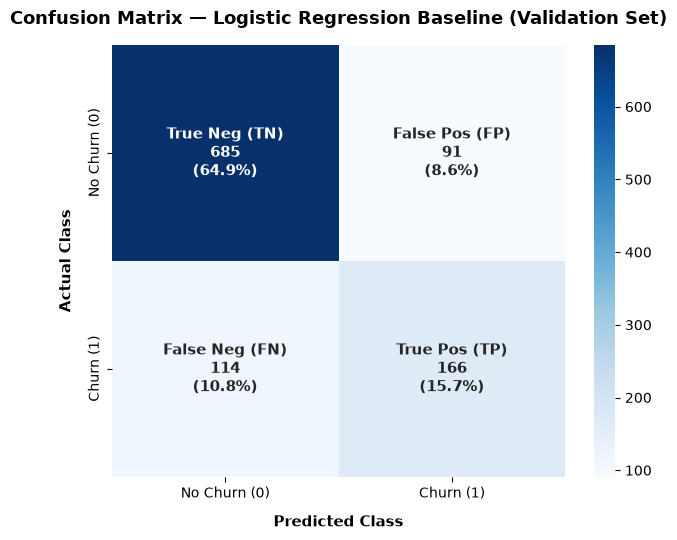

In [9]:
cm = compute_confusion_matrix(y_val, y_val_pred)
breakdown = get_confusion_matrix_breakdown(y_val, y_val_pred)

print(
    f"True Negatives  (TN): {breakdown['tn']} ({breakdown['tn'] / len(y_val) * 100:.2f}%)"
)
print(
    f"False Positives (FP): {breakdown['fp']} ({breakdown['fp'] / len(y_val) * 100:.2f}%)"
)
print(
    f"False Negatives (FN): {breakdown['fn']} ({breakdown['fn'] / len(y_val) * 100:.2f}%)"
)
print(
    f"True Positives  (TP): {breakdown['tp']} ({breakdown['tp'] / len(y_val) * 100:.2f}%)"
)

fig = plot_confusion_matrix(
    cm,
    title="Confusion Matrix — Logistic Regression Baseline (Validation Set)",
    save_path=CONFUSION_MATRIX_FIGURE_PATH,
)
plt.show()

## 11. Classification Report

The per-class classification report evaluates precision, recall, and F1-score for both classes individually.

In [10]:
report = get_classification_report(y_val, y_val_pred)
print("Validation Set Classification Report:\n")
print(report)

Validation Set Classification Report:

              precision    recall  f1-score   support

    No Churn       0.86      0.88      0.87       776
       Churn       0.65      0.59      0.62       280

    accuracy                           0.81      1056
   macro avg       0.75      0.74      0.74      1056
weighted avg       0.80      0.81      0.80      1056



## 12. Baseline Results

We store and display the baseline metrics in a structured comparative format.

In [11]:
baseline_results = {
    "model": "Logistic Regression (Baseline)",
    "accuracy": metrics["accuracy"],
    "precision": metrics["precision"],
    "recall": metrics["recall"],
    "f1": metrics["f1"],
    "roc_auc": metrics["roc_auc"],
    "tn": breakdown["tn"],
    "fp": breakdown["fp"],
    "fn": breakdown["fn"],
    "tp": breakdown["tp"],
}

results_df = pd.DataFrame([baseline_results])
results_df

,model,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,Logistic Regression (Baseline),0.8059,0.6459,0.5929,0.6182,0.8454,685,91,114,166


## 13. Interpretation & Limitation Analysis

### 1. Overall Performance:
- **Accuracy (80.59%)**: The model correctly classifies approximately 80.6% of all validation cases.
- **ROC-AUC (0.8454)**: A score of 0.8454 indicates solid discriminative capability; if given a random churner and a random non-churner, the model assigns a higher probability to the churner 84.5% of the time.

### 2. The Accuracy Paradox (Why Accuracy is Misleading):
In an imbalanced dataset with ~26.5% churn:
- A trivial **Dummy Classifier** that blindly predicts `No Churn` for all 1,056 customers would achieve **73.48% accuracy**:
  $$\text{Dummy Accuracy} = \frac{776}{1056} = 73.48\%$$
- However, the dummy model would catch **zero churners** (Recall = 0.0, F1 = 0.0).
- Therefore, our model's 80.59% accuracy represents an improvement of only +7.11 percentage points over the majority-class baseline.

### 3. Recall vs. False Negatives:
- The model achieves a **Recall of 59.29%** on the churn class.
- Out of **280 actual churners**, the model successfully identifies **166 (TP)**, but misses **114 (FN)**.
- **40.7% of all churners slip through undetected**. From a retention perspective, this leaves substantial room for improvement in subsequent tree-based models and threshold tuning.

## 14. Save Model

We serialize the trained baseline model artifact to disk using `save_model()`.

In [12]:
saved_model_path = save_model(model, BASELINE_MODEL_PATH)
print(f"Trained baseline model successfully saved to: {saved_model_path}")

# Verify deserialization
loaded_baseline = load_model(BASELINE_MODEL_PATH)
loaded_preds = predict_churn(loaded_baseline, X_val)
assert np.array_equal(y_val_pred, loaded_preds), (
    "Loaded model predictions do not match!"
)
print("Reloaded model verified: identical validation predictions.")

Trained baseline model successfully saved to: /home/lenovo/Documents/customer churn prediction/models/logistic_regression_baseline.joblib
Reloaded model verified: identical validation predictions.


## 15. Baseline Findings

1. **Benchmark Established**: We have established an empirical benchmark (Accuracy: 0.8059, F1: 0.6182, ROC-AUC: 0.8454) using a reproducible, lightweight linear classifier.
2. **Identification Capability**: The baseline correctly identifies nearly 60% of at-risk customers with a precision of 64.6%.
3. **Primary Weakness**: The false negative rate (40.7%) is significant; complex non-linear models (Decision Tree, Random Forest, XGBoost) and threshold adjustments are needed to capture churners with complex interaction patterns.

## 16. Next Steps

In **Step 6: Multiple Model Training and Validation Comparison**, we will:
1. Train a **Decision Tree Classifier** to capture non-linear rule splits.
2. Train an ensemble **Random Forest Classifier** to evaluate bagging performance.
3. Compare all candidate models against this Logistic Regression baseline using the same validation set and identical evaluation metrics.